# Más allá: exposición conciliada con un motor de referencia dentro del error de Monte Carlo, y valores de referencia para la correlación adversa

- **Nivel:** 4, Más allá del estado del arte
- **Requisitos previos:** los notebooks 03, 06 y 07 de este tema
- **Tiempo de lectura:** unos 45 minutos

**Pregunta:** ¿Qué resultados del motor de contraparte pueden llamarse con honestidad conciliados con un motor de referencia, con las fallas impresas junto a los éxitos, y qué tan cerca llegan su calibración de correlación adversa y sus formas cerradas de los valores publicados que deben reproducir?

## Objetivos

Al terminar este notebook puedes:

- enunciar la afirmación BS-2 del SDD para el motor de contraparte, qué cubre y qué no afirma;
- recalcular la exposición del motor y compararla con el perfil versionado de ORE 1.8.17.0 dentro de errores estándar combinados de Monte Carlo, para las dos variantes donde la afirmación se cumple;
- leer las otras variantes como brechas informadas, con la cifra que dice qué tan grande es cada una;
- verificar las formas cerradas contra las filas de QuantLib, y la calibración de correlación adversa contra los dígitos impresos del Apéndice del artículo;
- decir por qué una conciliación que informa sus fallas es una evidencia más fuerte que una que informa solo sus éxitos.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.ccr import cva
from riskvalidation.ccr import exposure as ex
from riskvalidation.ccr import hw1f
from riskvalidation.ccr import swaps as sw
from riskvalidation.validation import ccr as vc

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

Las seis variantes del caso C12 (riesgo de crédito de contraparte) bajo `data/derived/C12/`, sobre swaps sintéticos y la curva a la par del Tesoro de EE. UU. del 2025-09-30 (clase de licencia `mirror-allowed`). Cada una lleva el bloque `ore_reconciliation` (ORE 1.8.17.0, corrido de forma nativa sobre las mismas operaciones y curva con 10.000 muestras antitéticas; no se corre aquí) y las pruebas del motor. Los notebooks 06 y 07 explican cada prueba; este las lee como evidencia de una afirmación.

- **Archivos que se leen:** los seis documentos `single-swap.json`, `netting-set.json`, `csa-mpor-10d.json`, `csa-mpor-20d.json`, `with-im.json` y `wrong-way-risk.json`.
- **Qué se recalcula en vivo:** la exposición esperada del motor para el swap único y para el conjunto de neteo, desde la curva, la calibración, la semilla y el número de trayectorias versionados (notebook 01), y la comparación con el perfil versionado de ORE; la calibración de correlación adversa del Apéndice del artículo.
- **Qué se lee:** los perfiles de ORE y las filas de comparación con QuantLib.

La celda siguiente carga los documentos y verifica que cada archivo versionado que cita la afirmación existe y fue calculado con la versión del motor instalada aquí.

In [2]:
# Cargar las seis variantes versionadas de C12 y verificar los archivos, la versión de cálculo y la clase de licencia
ROOT = Path("../../..").resolve()
names = ["single-swap", "netting-set", "csa-mpor-10d", "csa-mpor-20d", "with-im", "wrong-way-risk"]
paths = {n: ROOT / "data" / "derived" / "C12" / f"{n}.json" for n in names}
docs = {n: json.loads(p.read_text(encoding="utf-8")) for n, p in paths.items()}
LIGHT = {"green": "verde", "red": "rojo", "amber": "ámbar"}

present = all(p.is_file() for p in paths.values())
print("archivos presentes:", "sí" if present else "no", "| motor instalado:", rv.__version__)
print("calculado con riskvalidation, por variante:",
      {n: d["provenance"]["riskvalidation_version"] for n, d in docs.items()})
print("estado de verdad:", {d["provenance"]["truth_status"] for d in docs.values()})
print("clases de licencia de las entradas:", docs["single-swap"]["provenance"]["licence_classes"])
print("ORE versión:", docs["single-swap"]["outputs"]["ore_reconciliation"]["ore_version"])

archivos presentes: sí | motor instalado: 1.0.1
calculado con riskvalidation, por variante: {'single-swap': '1.0.1', 'netting-set': '1.0.1', 'csa-mpor-10d': '1.0.1', 'csa-mpor-20d': '1.0.1', 'with-im': '1.0.1', 'wrong-way-risk': '1.0.1'}
estado de verdad: {'synthetic-calibrated'}
clases de licencia de las entradas: {'treasury-par-curve': 'mirror-allowed', 'treasury-hqm': 'mirror-allowed'}
ORE versión: 1.8.17.0


## Método

### Paso 1: el lado del motor, recalculado

Para que la afirmación signifique algo el lado del motor no puede ser un número copiado de un archivo. Reconstruimos la exposición esperada del swap único y del conjunto de neteo desde la curva, la calibración, la semilla y el número de trayectorias (la construcción del notebook 01, con la misma grilla de tiempo), en la medida forward a la que se lleva el perfil descontado de ORE. La celda siguiente lo hace para ambas variantes, de modo que lo que comparamos con ORE se calcula aquí y no se copia de un archivo.

In [3]:
# Reconstruir la simulación del notebook 01 y la EE del swap único y del conjunto de neteo
base = docs["netting-set"]["outputs"]
tenors = np.array([p["tenor_years"] for p in base["curve"]["points"]])
zeros = np.array([p["zero_rate"] for p in base["curve"]["points"]])
a, sigma = base["calibration_used"]["a"], base["calibration_used"]["sigma"]
p0, forward = hw1f.curve_functions(zeros, tenors)
named = base["named_parameters"]
report = np.array(named["time_grid_years"]["value"])
main = np.concatenate([[0.0], report])
swaps = [
    sw.Swap(t["trade_id"], t["notional"]["amount"], t["fixed_rate"], t["side"] == "payer",
            t["start_years"], t["maturity_years"], t["fixed_frequency_per_year"])
    for t in base["book"]["trades"]
]
merged = np.unique(np.round(np.concatenate([main] + [main + d for d in (14 / 360, 28 / 360)]), 12))
grid = sw.simulation_grid(merged, swaps)
r = hw1f.simulate_short_rate(grid, a, sigma, forward, named["path_count"]["value"], named["seed"]["value"])
numeraire = hw1f.bank_account(grid, r, a, sigma, p0, forward)
values = sw.swap_values_on_grid(swaps, grid, r, a, sigma, p0, forward)
ix = np.searchsorted(grid, report - sw.TIME_TOL)
p0r, nm = p0(report), numeraire[:, ix]

live = {}
for key, members in (("single-swap", [0]), ("netting-set", [0, 1, 2, 3])):
    e_d, e_se = ex.expected_exposure(ex.net_values(values[members][:, :, ix]), nm)
    live[key] = (e_d / p0r, e_se / p0r)
    print(f"{key:12s} máximo de la EE reconstruida:", round(float(live[key][0].max()), 0),
          "en", float(report[live[key][0].argmax()]), "a")

single-swap  máximo de la EE reconstruida: 294524.0 en 5.0 a
netting-set  máximo de la EE reconstruida: 294524.0 en 5.0 a


### Paso 2: la conciliación con ORE

Ahora el perfil reconstruido del motor se enfrenta al versionado de ORE, punto a punto, con `reconcile_ee_profile` del motor, cada lado con su propio error de Monte Carlo. Esta es la afirmación en su forma más nítida: dos implementaciones independientes, una en Python y una en C++, del mismo modelo de Hull-White sobre la misma curva y operaciones, con la diferencia medida en unidades de su propio ruido. Para la EEPE y el CVA el error combinado es el registrado en el documento. La celda siguiente imprime, para las dos variantes de la afirmación, el estadístico, el número de fechas dentro del umbral, y las diferencias de EEPE y CVA.

In [4]:
# Conciliar la EE reconstruida de las dos variantes con el perfil de ORE, y leer las diferencias de EEPE y CVA
print(f"{'variante':13s}{'estadístico':>12s}{'fechas dentro de 2 se':>26s}{'luz':>8s}"
      f"{'EEPE (se)':>12s}{'CVA (se)':>11s}")
for key in ("single-swap", "netting-set"):
    o = docs[key]["outputs"]["ore_reconciliation"]
    ref, ref_se = np.array(o["ore_ee"]["values"]), np.array(o["ore_ee"]["mc_se"])
    t = vc.reconcile_ee_profile(live[key][0], live[key][1], ref, ref_se, k_se=2.0)
    inside = int(np.sum(np.abs(live[key][0] - ref) <= 2.0 * np.sqrt(live[key][1] ** 2 + ref_se**2)))
    e, c = o["eepe_agreement"], o["cva_agreement"]
    print(f"{key:13s}{t.statistic:12.3f}{inside:22d} /{report.size:3d}{LIGHT[t.light.value]:>8s}", end="")
    print(f"{e['difference'] / e['combined_se']:12.2f}{c['difference'] / c['combined_se']:11.2f}")
print("umbral (k_se):", t.extras["thresholds"]["k_se"])

variante      estadístico     fechas dentro de 2 se     luz   EEPE (se)   CVA (se)
single-swap         0.775                    33 / 33   verde        0.30       0.37
netting-set         0.715                    33 / 33   verde        0.31       0.40
umbral (k_se): 2.0


La celda siguiente dibuja la EE reconstruida del swap único y del conjunto de neteo sobre el perfil de ORE, con una banda de dos errores estándar combinados alrededor del de ORE.

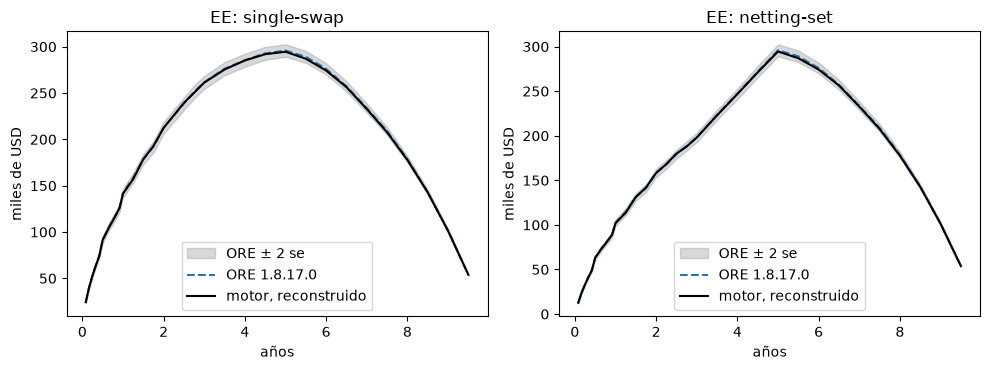

In [5]:
# Dibujar la EE reconstruida sobre el perfil de ORE para ambas variantes, con una banda de 2 se combinados
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, key in zip(axes, ("single-swap", "netting-set")):
    o = docs[key]["outputs"]["ore_reconciliation"]
    ref, ref_se = np.array(o["ore_ee"]["values"]), np.array(o["ore_ee"]["mc_se"])
    band = 2 * np.sqrt(live[key][1] ** 2 + ref_se**2)
    ax.fill_between(report, (ref - band) / 1e3, (ref + band) / 1e3, color="grey", alpha=0.3, label="ORE ± 2 se")
    ax.plot(report, ref / 1e3, "--", color="tab:blue", label="ORE 1.8.17.0")
    ax.plot(report, live[key][0] / 1e3, color="black", lw=1.5, label="motor, reconstruido")
    ax.set_xlabel("años")
    ax.set_ylabel("miles de USD")
    ax.set_title(f"EE: {key}")
    ax.legend()
fig.tight_layout()
plt.show()

En ambos paneles la línea negra corre dentro de la banda gris, el error combinado de los dos motores, de la primera fecha a la última, y sigue la línea segmentada de ORE a través del máximo. Esta es la afirmación en su forma más nítida: una simulación en Python y una en C++ del mismo modelo de Hull-White, escritas de forma independiente, producen perfiles que no se distinguen dado su propio ruido. La banda tiene dos errores estándar combinados de ancho, un umbral fijado antes de mirar los datos. Los paneles cubren dos carteras sin garantía; la sección siguiente pasa a las carteras donde la afirmación no se cumple.

## Estado del arte

Qué ofrece la práctica, tal como la investigación persistida del caso la registra desde las fuentes primarias. Las herramientas de exposición de contraparte dan los estimadores y la simulación y dejan la conciliación al usuario: ORE es el motor abierto más completo y la referencia natural, y QuantLib aporta las formas cerradas del modelo de Hull-White; ninguno trae una declaración de cuánto coincide con él una implementación independiente. La regla de la propia investigación para Contraste es que los números de ORE y de QuantLib pueden presentarse como una validación del producto **solo hasta donde llegan las conciliaciones realmente corridas**, nunca más allá. La práctica de ingeniería detrás de una conciliación es la que se usa en este tema: ambos lados llevan un error de Monte Carlo, la diferencia se enuncia en errores estándar combinados, y se fija un umbral antes de la comparación, aquí dos errores estándar combinados, un umbral interno de Contraste y no uno regulatorio.

## Más allá del estado del arte

Este notebook demuestra la afirmación **BS-2** del SDD, para el motor de contraparte: las conciliaciones contra motores de referencia que existen hoy, y la brecha informada.

- **Qué se afirma.** La exposición del motor para el swap único y para el conjunto de neteo coincide con ORE 1.8.17.0 en cada una de las 33 fechas del informe dentro de dos errores estándar combinados de Monte Carlo, y también la EEPE y el CVA. Las opciones sobre bonos y las swaptions de Hull-White del motor coinciden con QuantLib 1.44 a un $10^{-6}$ relativo. La calibración de correlación adversa reproduce los valores impresos del Apéndice de Hull y White (2012): las tasas de riesgo a media unidad del último dígito impreso y el $a(t^*)$ impreso a 1,32 unidades.
- **Qué se informa como brecha y no se afirma.** Las variantes con garantía (CSA de 10 y de 20 días) y la variante con margen inicial no coinciden con ORE: las mayores brechas del perfil de EE son 9,9, 7,1 y 11,7 errores estándar combinados, el CVA difiere en 15,9 y 9,9 errores estándar en las dos variantes de CSA, y el margen inicial dinámico medio de ORE es 0,88 del del motor. El documento las registra como hallazgos con una causa identificada en parte (el monto mínimo de transferencia) y abierta en parte.
- **Qué no se afirma en absoluto.** La variante de correlación adversa contra ORE (otro modelo: no hay referencia), y el modelo contra el mercado (notebook 06: se rechaza).
- **Por qué esto va más allá.** La investigación encontró herramientas que traen estimadores y dejan la conciliación al usuario, y una regla de que los números de motores de referencia no deben afirmarse más allá de las conciliaciones realmente corridas. Contraste las corre, a la vista, con las fallas impresas junto a los éxitos, sobre archivos versionados que cualquiera puede reabrir.

La evidencia está en los documentos versionados (listados en la afirmación del SDD), y cada número de arriba lo imprimen las celdas de este notebook.

### Paso 3: las brechas, informadas

La afirmación cubre las variantes donde la conciliación se cumple, y el documento informa las otras. La celda siguiente lee las seis variantes y las ordena con la regla del propio documento: conciliada, brecha informada o no aplicable. Para cada una muestra el número de fechas de EE dentro del umbral, las diferencias de EEPE y CVA en errores estándar combinados, y para la variante con margen inicial la razón de los dos DIM medios. Nada se oculta promediando: se imprime la mayor brecha de cada perfil.

In [6]:
# Ordenar las seis variantes con la regla del propio documento e imprimir el tamaño de cada brecha informada
claimed, gaps, na, worst = [], [], [], {}
print(f"{'variante':15s}{'veredicto':18s}{'fechas de EE en 2 se':>24s}{'mayor brecha de EE (se)':>28s}"
      f"{'EEPE (se)':>11s}{'CVA (se)':>10s}")
for n in names:
    o = docs[n]["outputs"]
    rec = o["ore_reconciliation"]
    if rec["status"] == "not-applicable":
        na.append(n)
        print(f"{n:15s}{'no aplicable':18s}")
        continue
    ag = rec["agreement"]
    inside = sum(p["within_two_se"] for p in ag)
    worst[n] = max(abs(p["difference"]) / p["combined_se"] for p in ag)
    verdict = "afirmada" if rec["all_within_two_se"] else "brecha informada"
    (claimed if rec["all_within_two_se"] else gaps).append(n)
    e, c = rec["eepe_agreement"], rec["cva_agreement"]
    print(f"{n:15s}{verdict:18s}{inside:20d} /{len(ag):3d}{worst[n]:28.1f}", end="")
    print(f"{e['difference'] / e['combined_se']:11.2f}{c['difference'] / c['combined_se']:10.2f}")
print("afirmadas:", claimed, "| brecha informada:", gaps, "| no aplicables:", na)

variante       veredicto             fechas de EE en 2 se     mayor brecha de EE (se)  EEPE (se)  CVA (se)
single-swap    afirmada                            33 / 33                         0.8       0.30      0.37
netting-set    afirmada                            33 / 33                         0.7       0.31      0.40
csa-mpor-10d   brecha informada                    17 / 33                         9.9      -1.55    -15.89
csa-mpor-20d   brecha informada                    21 / 33                         7.1      -2.20     -9.88
with-im        brecha informada                    32 / 33                        11.7      -0.71     -1.40
wrong-way-risk no aplicable      
afirmadas: ['single-swap', 'netting-set'] | brecha informada: ['csa-mpor-10d', 'csa-mpor-20d', 'with-im'] | no aplicables: ['wrong-way-risk']


La variante con margen inicial tiene un número más que leer: el margen inicial dinámico medio de ambos motores, y los hallazgos que el propio caso registró contra ORE para las variantes con brecha. La celda siguiente imprime ambos.

In [7]:
# La razón de los dos DIM medios, el estadístico sobre el perfil del DIM, y los hallazgos contra ORE
im = docs["with-im"]["outputs"]
dim_py, dim_py_se = np.array(im["initial_margin"]["dim"]["values"]), np.array(im["initial_margin"]["dim"]["mc_se"])
dim_ore = np.array(im["ore_reconciliation"]["ore_dim"]["values"])
dim_ore_se = np.array(im["ore_reconciliation"]["ore_dim"]["mc_se"])
t_dim = vc.reconcile_ee_profile(dim_py, dim_py_se, dim_ore, dim_ore_se, k_se=2.0)
dim_points = im["ore_reconciliation"]["dim_agreement"]
print("margen inicial: puntos del DIM medio dentro del umbral:",
      sum(p["within_two_se"] for p in dim_points), "de", len(dim_points))
print("razón del DIM medio ORE / motor:", round(float(np.mean(dim_ore / dim_py)), 3),
      "| mayor brecha en se combinados:", round(t_dim.statistic, 1))
print("hallazgos registrados por el caso contra ORE (variante: títulos):")
for n in gaps:
    titles = [f["title"]["es"][:70] for f in docs[n]["findings"] if "ORE" in f["title"]["es"]]
    print(" ", n, titles)

margen inicial: puntos del DIM medio dentro del umbral: 0 de 33
razón del DIM medio ORE / motor: 0.884 | mayor brecha en se combinados: 137.4
hallazgos registrados por el caso contra ORE (variante: títulos):
  csa-mpor-10d ['1 fila roja sobre el CVA frente a ORE 1.8.17.0', '1 fila roja sobre el perfil de EE frente a ORE 1.8.17.0', '1 fila roja sobre el perfil de EE frente a ORE 1.8.17.0 (monto mínimo ']
  csa-mpor-20d ['1 fila roja sobre el CVA frente a ORE 1.8.17.0', '1 fila roja sobre el EEPE frente a ORE 1.8.17.0', '1 fila roja sobre el perfil de EE frente a ORE 1.8.17.0', '1 fila roja sobre el perfil de EE frente a ORE 1.8.17.0 (monto mínimo ']
  with-im ['1 fila roja sobre el margen inicial medio frente al margen inicial din', '1 fila roja sobre el perfil de EE frente a ORE 1.8.17.0']


La celda siguiente dibuja la mayor brecha estandarizada del perfil de EE de cada variante frente al umbral de dos errores estándar, y la brecha a lo largo de las fechas para el swap único y el CSA de 10 días.

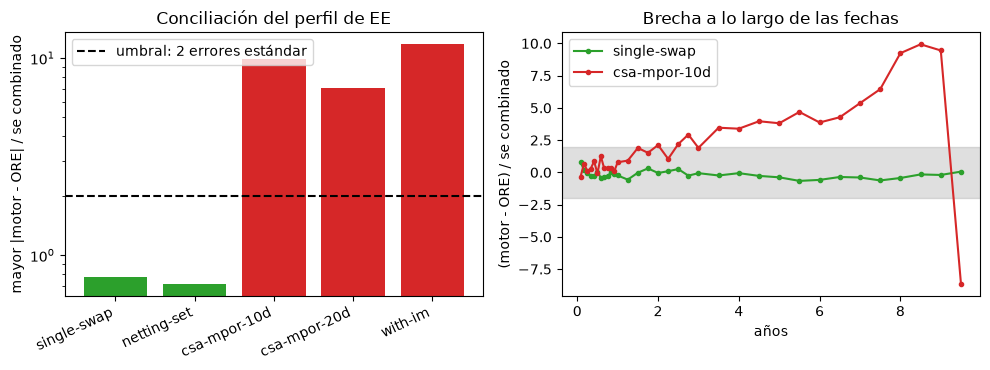

In [8]:
# Dibujar la mayor brecha de EE por variante frente al umbral (izquierda) y a lo largo de las fechas (derecha)
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))
checked = [n for n in names if n not in na]
colors = ["tab:green" if n in claimed else "tab:red" for n in checked]
left.bar(range(len(checked)), [worst[n] for n in checked], color=colors)
left.axhline(2.0, color="black", ls="--", label="umbral: 2 errores estándar")
left.set_yscale("log")
left.set_xticks(range(len(checked)), checked, rotation=25, ha="right")
left.set_ylabel("mayor |motor - ORE| / se combinado")
left.set_title("Conciliación del perfil de EE")
left.legend()
for n, color in (("single-swap", "tab:green"), ("csa-mpor-10d", "tab:red")):
    ag = docs[n]["outputs"]["ore_reconciliation"]["agreement"]
    gap = [-p["difference"] / p["combined_se"] for p in ag]
    right.plot([p["t"] for p in ag], gap, "o-", ms=3, color=color, label=n)
right.axhspan(-2, 2, color="grey", alpha=0.25)
right.set_xlabel("años")
right.set_ylabel("(motor - ORE) / se combinado")
right.set_title("Brecha a lo largo de las fechas")
right.legend()
fig.tight_layout()
plt.show()

A la izquierda, las dos variantes afirmadas quedan bajo el umbral segmentado y las tres variantes con garantía quedan sobre él por un factor de cuatro a seis, en una escala logarítmica que hace parecer la brecha menor de lo que es. A la derecha, el swap único oscila dentro de la banda gris mientras el CSA de 10 días corre fuera de ella durante un largo tramo de fechas, hacia un solo lado. Nada se promedia hasta desaparecer: se grafica la mayor brecha de cada perfil. El caso registra estas brechas como hallazgos, con el monto mínimo de transferencia como la parte de la causa ya identificada, y la figura es la evidencia que necesita un lector para cuestionarlo.

### Paso 4: las otras referencias

Otras dos referencias respaldan la afirmación. Primero, las formas cerradas del modelo de Hull-White contra QuantLib 1.44, como cuatro filas con ambos valores y un umbral de $10^{-6}$ en términos relativos. Segundo, la variante de correlación adversa no tiene referencia en ORE, porque el ejemplo de ORE es otro modelo; su referencia es el Apéndice de Hull y White (2012), que imprime una calibración de tres trayectorias. Los dígitos del artículo son los valores de referencia: el $a(t^*)$ impreso y las tasas de riesgo $h_{ij}$. `wwr_calibrate_a`, del motor, debe darlos, y en $b=0$ `wwr_cva` debe devolver el CVA independiente de forma exacta. Las dos celdas siguientes verifican las cuatro cosas.

In [9]:
# Las cuatro filas de QuantLib, y los valores del Apéndice frente a la calibración de correlación adversa
ql = [row for row in docs["single-swap"]["tests"] if row["test_id"].startswith("ccr.quantlib")]
rel = [abs(row["extras"]["engine"] - row["extras"]["quantlib"]) / abs(row["extras"]["quantlib"]) for row in ql]
print("filas de QuantLib:", len(ql), "| mayor diferencia relativa:", f"{max(rel):.2e}",
      "| el umbral 1e-6 se cumple:", "sí" if max(rel) < 1e-6 else "no")

w_app = np.array([[100.0, 100.0], [200.0, 300.0], [300.0, 400.0]])
target = cva.survival_from_spread(np.array([0.01, 0.01]), np.array([0.5, 1.0]), 1.0)
a_app, h_app = cva.wwr_calibrate_a(w_app, target, np.array([0.5, 0.5]), 0.01)
printed_a = np.array([-6.9128, -7.8509])
printed_h = np.array([[0.00270, 0.00735, 0.01998], [0.00106, 0.00782, 0.02126]])
unit_a, unit_h = 1e-4, 1e-5
print("a(t*) brecha con los dígitos impresos, en unidades del último dígito impreso:",
      np.round(np.abs(a_app - printed_a) / unit_a, 2))
print("h mayor brecha, en unidades del último dígito impreso:",
      round(float(np.max(np.abs(h_app.T - printed_h)) / unit_h), 2))
mean_survival = np.exp(-np.cumsum(h_app * 0.5, axis=1)).mean(axis=0)
print("mayor brecha entre la supervivencia promedio tras cada paso y la meta:",
      float(np.max(np.abs(mean_survival - target))))

filas de QuantLib: 4 | mayor diferencia relativa: 9.50e-08 | el umbral 1e-6 se cumple: sí
a(t*) brecha con los dígitos impresos, en unidades del último dígito impreso: [0.33 1.32]
h mayor brecha, en unidades del último dígito impreso: 0.45
mayor brecha entre la supervivencia promedio tras cada paso y la meta: 1.1102230246251565e-16


La segunda celda recalcula la variante de correlación adversa: en $b=0$ el CVA con correlación adversa debe ser exactamente el CVA independiente, y en $b=1$ y $b=2$ debe subir en los montos que da el barrido.

In [10]:
# El CVA con correlación adversa en b = 0 contra el CVA independiente, y su alza en b = 1 y b = 2
wwr = docs["wrong-way-risk"]["outputs"]
credit = wwr["cva_dva"]
survival = np.array([b["survival"] for b in credit["buckets"]])
dt = np.diff(np.concatenate([[0.0], report]))
v_net = ex.net_values(values[:, :, ix])
w, x_disc = v_net / 1e6, np.maximum(v_net, 0.0) / nm
epe_d = np.array(wwr["exposure"]["ee_discounted"]["values"])
pd_cp = cva.default_probabilities(np.concatenate([[1.0], survival]))
independent, _ = cva.cva(epe_d, pd_cp, credit["lgd"])
value0, _ = cva.wwr_cva(w, x_disc, survival, dt, credit["lgd"], 0.0)
print("el CVA con correlación adversa en b = 0 es igual al CVA independiente:",
      "sí" if value0 == independent else "no", "|", round(independent, 2))
for b in (1.0, 2.0):
    value, _ = cva.wwr_cva(w, x_disc, survival, dt, credit["lgd"], b)
    print(f"b = {b:.0f} | CVA {value:10.2f} | cambio frente al independiente {value / independent - 1:+.1%}")

el CVA con correlación adversa en b = 0 es igual al CVA independiente: sí | 9477.77
b = 1 | CVA   12439.56 | cambio frente al independiente +31.2%
b = 2 | CVA   15594.61 | cambio frente al independiente +64.5%


## Resultados

**Respuesta:** Dos de las seis variantes concilian con ORE 1.8.17.0 dentro del error de Monte Carlo: el swap único, con una mayor brecha de 0,775 errores estándar combinados, y el conjunto de neteo de cuatro swaps, con 0,715, ambos con las 33 fechas dentro del umbral de 2. Tres no concilian y lo dicen: el CSA de 10 días (9,9 errores estándar), el CSA de 20 días (7,1) y la variante con margen inicial (11,7), donde el margen inicial dinámico medio de ORE es 0,884 del del motor; una no tiene referencia. Las swaptions del motor coinciden con QuantLib hasta una diferencia relativa de 9,5e-8, y su calibración de correlación adversa reproduce los valores impresos del artículo con a lo más 1,32 unidades del último dígito impreso.

- **El lado del motor se calcula aquí.** La exposición esperada del swap único y del conjunto de neteo se reconstruye desde la curva, la calibración, la semilla y el número de trayectorias, así que lo que se compara con ORE no es un número copiado de un archivo. La EEPE difiere en 0,30 y 0,31 errores estándar y el CVA en 0,37 y 0,40. El motor corrió 20.000 trayectorias; ORE corrió 10.000 muestras antitéticas de forma nativa en cerca de medio minuto.
- **Dónde no, y por cuánto.** El CSA de 10 días tiene 17 de 33 fechas dentro del umbral, una EEPE dentro del umbral (-1,55) y un CVA a 15,9 errores estándar (ORE es menor). El CSA de 20 días tiene 21 de 33 fechas dentro, y tanto la EEPE (-2,20) como el CVA (-9,88) fuera del umbral. Con margen inicial 32 de 33 fechas de EE están dentro del umbral (mayor brecha 11,7, en una fecha), la EEPE y el CVA coinciden (-0,71 y -1,40), y ninguno de los 33 puntos del margen inicial dinámico medio lo está. El caso registra cada una como un hallazgo.
- **Formas cerradas y valores de referencia.** Las cuatro filas de QuantLib coinciden hasta una diferencia relativa de 9,5e-8 como máximo, dentro del umbral de 1e-6. La calibración de correlación adversa reproduce las tasas de riesgo del Apéndice del artículo hasta 0,45 de una unidad del último dígito impreso, el $a(t_1^*)$ impreso hasta 0,33 y el $a(t_2^*)$ impreso hasta 1,32 unidades (el artículo imprime -7,8509 y la raíz de su propia ecuación, que el motor encuentra, se redondea a -7,8508); la supervivencia promedio es igual a la meta hasta 1e-12. En $b=0$ el CVA con correlación adversa es exactamente el CVA independiente, y en $b=1$ y $b=2$ está 31,2% y 64,5% sobre él.
- **Qué es la afirmación.** Dos de las seis variantes concilian con el motor de referencia dentro del error de Monte Carlo; tres no y lo dicen; una no tiene referencia. Un lector que quiera cuestionar la afirmación tiene los perfiles de ambos motores en los documentos versionados y el umbral en la prueba del motor.

Lo que este notebook no muestra: por qué difieren las variantes con garantía (el monto mínimo de transferencia explica la mayor parte de la brecha del CSA en el documento, y la causa restante y la diferencia del DIM están abiertas), una conciliación de los otros motores del producto (cartera, IRRBB, liquidez) con una referencia, ni una afirmación de que el modelo de Hull-White describe el mercado (notebook 06: la prueba retrospectiva lo rechaza).

## Resumen

- BS-2 para el motor de contraparte: la exposición del swap único y del conjunto de neteo coincide con ORE 1.8.17.0 en cada fecha dentro de dos errores estándar combinados, y con QuantLib 1.44 en las formas cerradas.
- La misma conciliación informa sus fallas: las variantes de CSA y el margen inicial dinámico difieren de ORE, con el tamaño de cada brecha impreso y los hallazgos registrados.
- La calibración de correlación adversa no tiene referencia en ORE, así que sus valores de referencia son los dígitos impresos del Apéndice del artículo, igualados a cerca de una unidad del último dígito, y la identidad en $b=0$.
- Una conciliación es evidencia sobre dos implementaciones de un modelo; no dice nada sobre si el modelo se ajusta al mercado.

**Qué probar después.** Aprieta el umbral a 1 error estándar y cuenta qué variantes siguen afirmadas; lista los hallazgos de cada documento y compara sus títulos con las brechas impresas aquí. Este es el último notebook del tema.

## Referencias

- Open Source Risk Engine (ORE), release 1.8.17.0. https://github.com/OpenSourceRisk/Engine
- Open Source Risk Engine, Methodology, value adjustments and margin period of risk (xva.tex at tag 1.8.17.0). https://github.com/OpenSourceRisk/Engine/blob/1.8.17.0/Docs/UserGuide/methods/xva.tex
- QuantLib, the open-source quantitative finance library. https://github.com/lballabio/QuantLib
- Hull, J. and White, A. (2012), CVA and wrong way risk, Financial Analysts Journal 68(5), 58-69. https://doi.org/10.2469/faj.v68.n5.6